In [2]:
!pip install pandas
!pip install plotly
!pip install sqlite3
!pip install statsmodels
!pip install scikit-learn
# Import libraries
import sqlite3
import pandas as pd
import plotly.express as px
import plotly.io as pio
import numpy as np
import statsmodels.api as sm
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from matplotlib.colors import ListedColormap
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 8)



ERROR: Could not find a version that satisfies the requirement sqlite3 (from versions: none)
ERROR: No matching distribution found for sqlite3


In [3]:
# 2. Connect to the database file (update filename if needed)
conn = sqlite3.connect(r"C:\Users\Admin\OneDrive\Documents\GIDEON FINA 1141\New folder\NEW_ECON1205.db")

In [4]:
# 3. Read in the tables
df_countries = pd.read_sql_query("SELECT * FROM countries", conn)
df_gdp = pd.read_sql_query("SELECT * FROM GDP", conn)
df_unemployment = pd.read_sql_query("SELECT * FROM Unemployment", conn)
df_expenditure = pd.read_sql_query("SELECT * FROM Expenditure", conn)
df_inflation = pd.read_sql_query("SELECT * FROM Inflation", conn)
df_population = pd.read_sql_query("SELECT * FROM Population", conn)
conn.close()

In [5]:
# 4. Rename the 2025 data columns to concise variable names
df_gdp = df_gdp.rename(columns={"2025 [YR2025]": "gdp"})
df_unemployment = df_unemployment.rename(columns={"2025 [YR2025]": "unemployment"})
df_population = df_population.rename(columns={"2025 [YR2025]": "population"})
df_expenditure = df_expenditure.rename(columns={"2025 [YR2025]": "expenditure"})
df_inflation = df_inflation.rename(columns={"2025 [YR2025]": "inflation"})

In [6]:
# 5. Merge indicator tables on Country Code
df = (
    df_unemployment[["Country Code", "unemployment"]]
    .merge(df_gdp[["Country Code", "gdp"]], on="Country Code", how="inner")
    .merge(df_inflation[["Country Code", "inflation"]], on="Country Code", how="inner")
    .merge(df_population[["Country Code", "population"]], on="Country Code", how="inner")
    .merge(df_expenditure[["Country Code", "expenditure"]], on="Country Code", how="inner")
)

In [7]:
# 6. Merge with the countries table to map codes to official country names
df = pd.merge(
    left=df,
    right=df_countries,
    left_on="Country Code",
    right_on="country_code",
    how="inner"
)

In [8]:
# 7. Data Cleaning: Convert '..' and strings into proper numeric values and drop NaNs
df["gdp"] = pd.to_numeric(df["gdp"], errors="coerce")
df["gdp_billion"] = df["gdp"] / 1e9  # Convert GDP to billions for better readability
df["unemployment"] = pd.to_numeric(df["unemployment"], errors="coerce")
df["population"] = pd.to_numeric(df["population"], errors="coerce")
df["population_million"] = df["population"] / 1e6  # Convert Population to millions for better readability
df["expenditure"] = pd.to_numeric(df["expenditure"], errors="coerce")
df["expenditure_billion"] = df["expenditure"] / 1e9  # Convert Expenditure to billions for better readability
df["inflation"] = pd.to_numeric(df["inflation"], errors="coerce")
df_clean = df.dropna(subset=["gdp", "unemployment", "population", "expenditure", "inflation"]).copy()

In [9]:
# 8. Interactive Plotly Scatter Plot
fig = px.scatter(
    df_clean,
    x="gdp",
    y="unemployment",
    hover_name="country_code",
    hover_data={
        "Country Code": True,
        "gdp": ":,.0f",
        "unemployment": ":.2f"
    },
    labels={
        "gdp": "GDP (constant 2015 US$)",
        "unemployment": "Unemployment (% of labor force)"
    },
    title="Unemployment Rate vs. GDP in 2025",
    log_x=True  # Log scale handles the wide skew across national GDP levels
)

In [10]:
# 9 Set the renderer to open the graph in your default web browser
pio.renderers.default = "browser"

fig.update_layout(template="plotly_white")
fig.show()

In [38]:
# 11 Plot a bar chart for all countries showing the relationship between Population, Unemployment
df_top10 = df_clean.nlargest(10, "gdp")
fig_bar = px.bar(   
    df_clean,
    x="expenditure_billion",
    y="country_code",
    color="country_code",
    hover_name="country_code",
    hover_data={
        "Country Code": True,
        "country_name": ":,.3f",
        "country_code": ":.8f"
    },
    labels={
        "expenditure_billion": "Government Expenditure (constant 2015 US$) in Billions"
    },
    title="Country vs. Government Expenditure in 2025 (Bar Chart)",
    log_x=True  # Log scale handles the wide skew across national GDP levels
)
fig_bar.show()

In [39]:
# 13 Clustering Unemployment and Inflation across the top 10 countries by GDP
df_top10 = df_clean.nlargest(10, "gdp")

fig_cluster = px.bar(
    df_top10,
    x="population_million",
    y=["unemployment", "inflation"],
    barmode="group",
    labels={
        "country_name": "Country",
        "value": "Percentage (%)",
        "variable": "Indicator"
    },
    title="Unemployment vs. Inflation Across Top 10 Economies (Clustered Bar Chart)"
)
fig_cluster.show()

In [33]:
# 14 plot a radar chart for all countries showing the relationship between Population, Unemployment, Expenditure and Inflation
# ==========================================
# CHART 4: Normalized Radar Chart (Top 5 Economies)
# ==========================================
# Min-Max normalize all indicators to [0, 1] across the full dataset
indicators = ["gdp", "expenditure", "population", "unemployment", "inflation"]
df_norm = df_clean[["country_code"] + indicators].copy()
for col in indicators:
    df_norm[col] = (df_norm[col] - df_norm[col].min()) / (df_norm[col].max() - df_norm[col].min())

# Select Top 5  developed countries by raw GDP for visual clarity
top5_countries = df_clean.nlargest(5, "gdp")["country_code"]
df_radar = df_norm[df_norm["country_code"].isin(top5_countries)].melt(
    id_vars="country_code",
    value_vars=indicators,
    var_name="Indicator",
    value_name="Normalized Score"
)

fig_radar = px.line_polar(
    df_radar,
    r="Normalized Score",
    theta="Indicator",
    color="country_code",
    line_close=True,
    range_r=[0, 1],
    title="4. Normalized Macroeconomic Profile: Top 5 Economies by GDP"
)
fig_radar.update_traces(fill="toself", opacity=0.35)
fig_radar.show()

In [35]:
# ==========================================
# CHART 1: Bubble Scatter Plot (Multivariate Scaling)
# ==========================================
fig_bubble = px.scatter(
    df_clean,
    x="gdp",
    y="expenditure",
    size="population",
    color="unemployment",
    hover_name="country_code",
    hover_data={
        "Country Code": True,  # <-- Space instead of underscore
        "gdp": ":,.0f",
        "expenditure": ":,.0f",
        "population": ":,.0f",
        "unemployment": ":.2f",
        "inflation": ":.2f"
    },
    log_x=True,
    log_y=True,
    size_max=45,
    color_continuous_scale="Viridis",
    labels={
        "gdp": "GDP (Log Scale)",
        "expenditure": "Expenditure (Log Scale)",
        "unemployment": "Unemployment (%)",
        "population": "Population"
    },
    title="1. Expenditure vs. GDP (Sized by Population, Colored by Unemployment)"
)
fig_bubble.show()

In [ ]:
# ==========================================
# CHART 2: Correlation Matrix Heatmap
# ==========================================
indicators = ["gdp", "expenditure", "population", "unemployment", "inflation"]

corr_matrix = df_clean[indicators].corr(method="pearson").round(2)

fig_corr = px.imshow(
    corr_matrix,
    text_auto=True,
    aspect="auto",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="2. Pearson Correlation Matrix Across Macroeconomic Indicators"
)
fig_corr.show()

In [34]:
# ==========================================
# CHART 3: 2D Density Heatmap with Marginal Histograms
# ==========================================
fig_density = px.density_heatmap(
    df_clean,
    x="unemployment",
    y="inflation",
    z="gdp",
    histfunc="avg",
    color_continuous_scale="Plasma",
    labels={
        "unemployment": "Unemployment Rate (%)",
        "inflation": "Inflation Rate (%)",
        "gdp": "Average GDP"
    },
    title="3. Average GDP Across Unemployment & Inflation Bins"
)
fig_density.show()

In [ ]:
# Marginal Distribution Scatter Plot
fig_marg = px.scatter(
    df_clean,
    x="log_expenditure",
    y="log_gdp",
    hover_name="country_code",
    trendline="ols",
    marginal_x="box",
    marginal_y="histogram",
    title="GDP vs Expenditure with OLS Fit & Marginal Distribution "
) 
fig_marg.show()

In [ ]:
# Clean column names (replace spaces with underscores for R compatibility)
df_clean = df_clean.rename(columns={"Country Code": "country_code_wb"})

In [ ]:
# Drop duplicate country code column if both exist
if "country_code" in df_clean.columns and "country_code_wb" in df_clean.columns:
    df_clean = df_clean.drop(columns=["country_code_wb"])

In [ ]:
# Export to CSV without the pandas index
df_clean.to_csv("econ_2025_clean.csv", index=False, encoding="utf-8")

CLASSIFICATION MODEL

In [14]:
# Create binary classification target above median GDP = 1, below median GDP = 0
# and two features: unemployment and inflation
df_clean["gdp_binary"] = (df_clean["gdp"] >= df_clean["gdp"].median()).astype(int)
df_clean["log_expenditure"] = np.log(df_clean["expenditure"].replace(0, np.nan))  # Avoid log(0)
df_clean["unemployment"] = df_clean["unemployment"].fillna(df_clean["unemployment"].median())
df_clean["inflation"] = df_clean["inflation"].fillna(df_clean["inflation"].median())

ds = df_clean[["country_code", "country_name", "gdp_binary", "unemployment", "inflation", "log_expenditure"]].copy()

#Eyeball
print(ds.head())

   country_code country_name  gdp_binary  unemployment  inflation  \
2           DZA  Contry Name           1        11.633   1.418352   
8           ARM  Contry Name           0        12.871   3.306933   
11          AUT  Contry Name           1         5.582   3.527194   
15          BGD  Contry Name           1         3.778   8.768763   
17          BLR  Contry Name           0         3.380   6.598779   

    log_expenditure  
2         26.279786  
8         23.671457  
11        26.722121  
15        26.632307  
17        24.982005  


The GDP was classified to separate country with GDP above the median and below the median to create a binary features. 

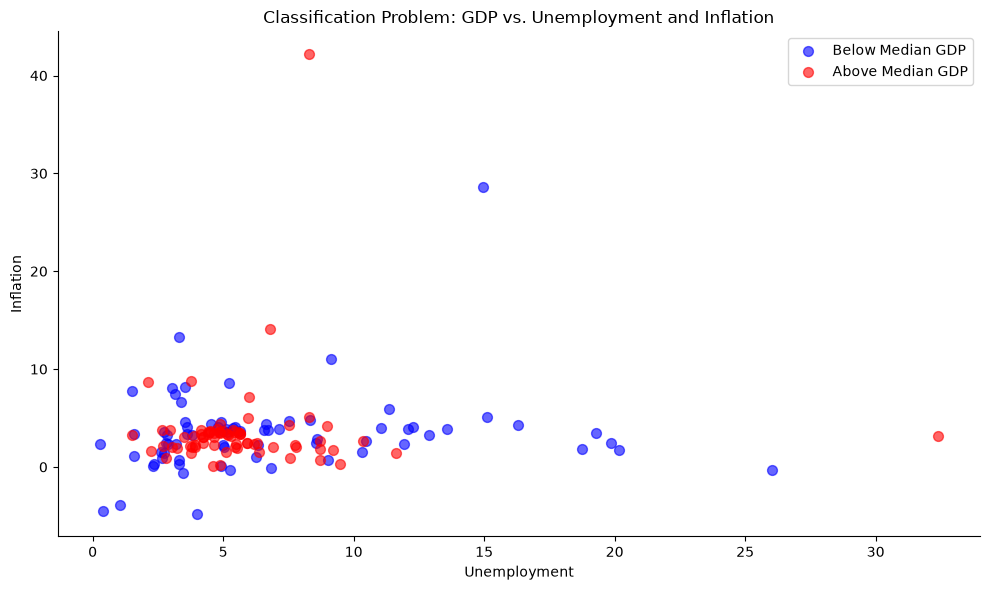

In [ ]:
# Eyeball the classification problem (scatter plot)

fig, ax = plt.subplots(figsize=(10, 6))
for label, color, name in [(0, 'blue', 'Below Median GDP'), (1, 'red', 'Above Median GDP')]:
    subset = ds[ds['gdp_binary'] == label]
    ax.scatter(subset['unemployment'], subset['inflation'], c=color, label=name, s=50, alpha=0.6)

ax.set_xlabel('Unemployment')
ax.set_ylabel('Inflation')
ax.set_title('Classification Problem: GDP vs. Unemployment and Inflation')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('classification_problem.png', dpi=300)
ax.legend()
plt.show()

# Feature matrix x and target vector y
X = ds[['unemployment', 'inflation']] 
y = ds['gdp_binary']

In [ ]:
# Discriminant Analysis (LDA)
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

# Add predictions to the dataset
ds['lda_pred'] = lda.predict(X)

# print LDA parameters
print("___ LDA Model Summary ___")
print("print probabilities:", dict(zip(lda.classes_, np.round(lda.priors_, 4))))
print("Group means:", pd.DataFrame(lda.means_, columns=X.columns, index=lda.classes_))
print("Coefficients of linear discriminants:", pd.Series(lda.coef_[0], index=X.columns))

___ LDA Model Summary ___
print probabilities: {np.int64(0): np.float64(0.4966), np.int64(1): np.float64(0.5034)}
Group means:    unemployment  inflation
0      6.904149   3.452520
1      5.774434   3.629678
Coefficients of linear discriminants: unemployment   -0.055688
inflation       0.014086
dtype: float64


In [ ]:
# Probit Model
x_probit = sm.add_constant(X)  # Add constant term for intercept
probit = sm.Probit(y, x_probit).fit()

# predict probabilities and classify at 0.5 threshold
pr_l = probit.predict(x_probit)
ds['probit_pred'] = (pr_l >= 0.5).astype(int)

print("___ Probit Model Summary ___")
print(probit.summary())


Optimization terminated successfully.
         Current function value: 0.685018
         Iterations 4
___ Probit Model Summary ___
                          Probit Regression Results                           
Dep. Variable:             gdp_binary   No. Observations:                  147
Model:                         Probit   Df Residuals:                      144
Method:                           MLE   Df Model:                            2
Date:                Sat, 21 Nov 2026   Pseudo R-squ.:                 0.01170
Time:                        22:08:27   Log-Likelihood:                -100.70
converged:                       True   LL-Null:                       -101.89
Covariance Type:            nonrobust   LLR p-value:                    0.3037
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1954      0.189      1.036      0.300      -0.174       

In [ ]:
# Support Vector Machine (SVM) Classifier (Linear Kernel, cost = 11)

svmfit = SVC(kernel='linear', C=11, probability=True)
svmfit.fit(X, y)

# Add predictions to the dataset
ds['svm_pred'] = svmfit.predict(X)

print("___ SVM Model Summary ___")
print(f"kernel: {svmfit.kernel}, C: {svmfit.C}")
print(f"Number of support vectors: {svmfit.n_support_.sum()} (per class: {svmfit.n_support_})")

___ SVM Model Summary ___
kernel: linear, C: 11
Number of support vectors: 138 (per class: [69 69])


c:\Users\Admin\OneDrive\Desktop\Gideon\New folder\.venv-1\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


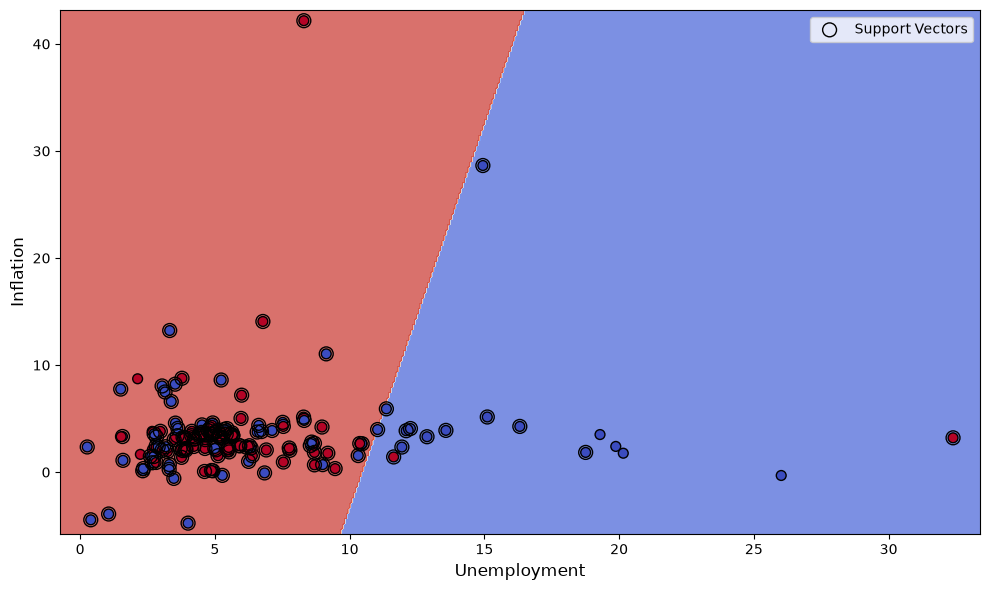

In [ ]:
# Plot SVM decision boundary
x_min, x_max = X['unemployment'].min() - 1, X['unemployment'].max() + 1
y_min, y_max = X['inflation'].min() - 1, X['inflation'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

grid_df = pd.DataFrame({"unemployment": xx.ravel(), "inflation": yy.ravel()})
z = svmfit.predict(grid_df).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 6))
ax.contourf(xx, yy, z, alpha=0.75, cmap=plt.cm.coolwarm)
ax.scatter(X['unemployment'], X['inflation'], c=y, edgecolors='k', cmap=plt.cm.coolwarm, s=50)

# Highlight support vectors with 'x' markers
ax.scatter(svmfit.support_vectors_[:, 0], svmfit.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k', label='Support Vectors')
ax.set_xlabel('Unemployment', fontsize=12)
ax.set_ylabel('Inflation', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

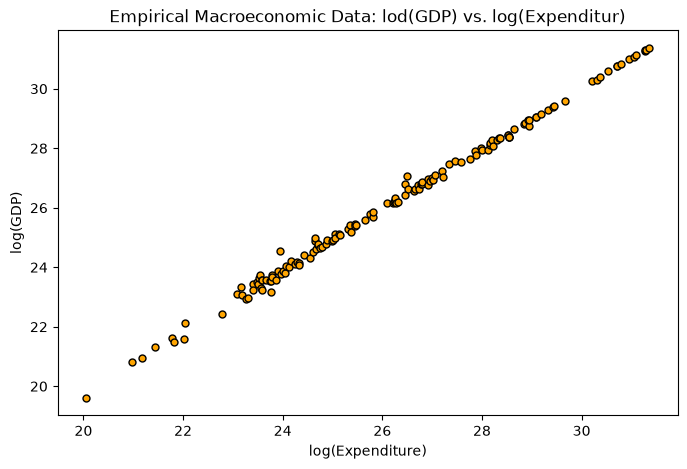

In [22]:
# Sort by log_expenditure for a clean 1D curve plotting
df_clean["log_gdp"] = np.log(df_clean["gdp"])
df_sorted = df_clean.sort_values(by="log_expenditure"). reset_index(drop=True)

x = df_sorted[["log_expenditure"]].values
y = df_sorted["log_gdp"].values

x_test = np.linspace(x.min(), x.max(), 500)[:, np.newaxis]

# Eyeball emperical data
plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=25, edgecolor="black", c="orange", label="2025 Economics")
plt.xlabel("log(Expenditure)")
plt.ylabel("log(GDP)")
plt.title("Empirical Macroeconomic Data: lod(GDP) vs. log(Expenditur)")
plt.legend
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

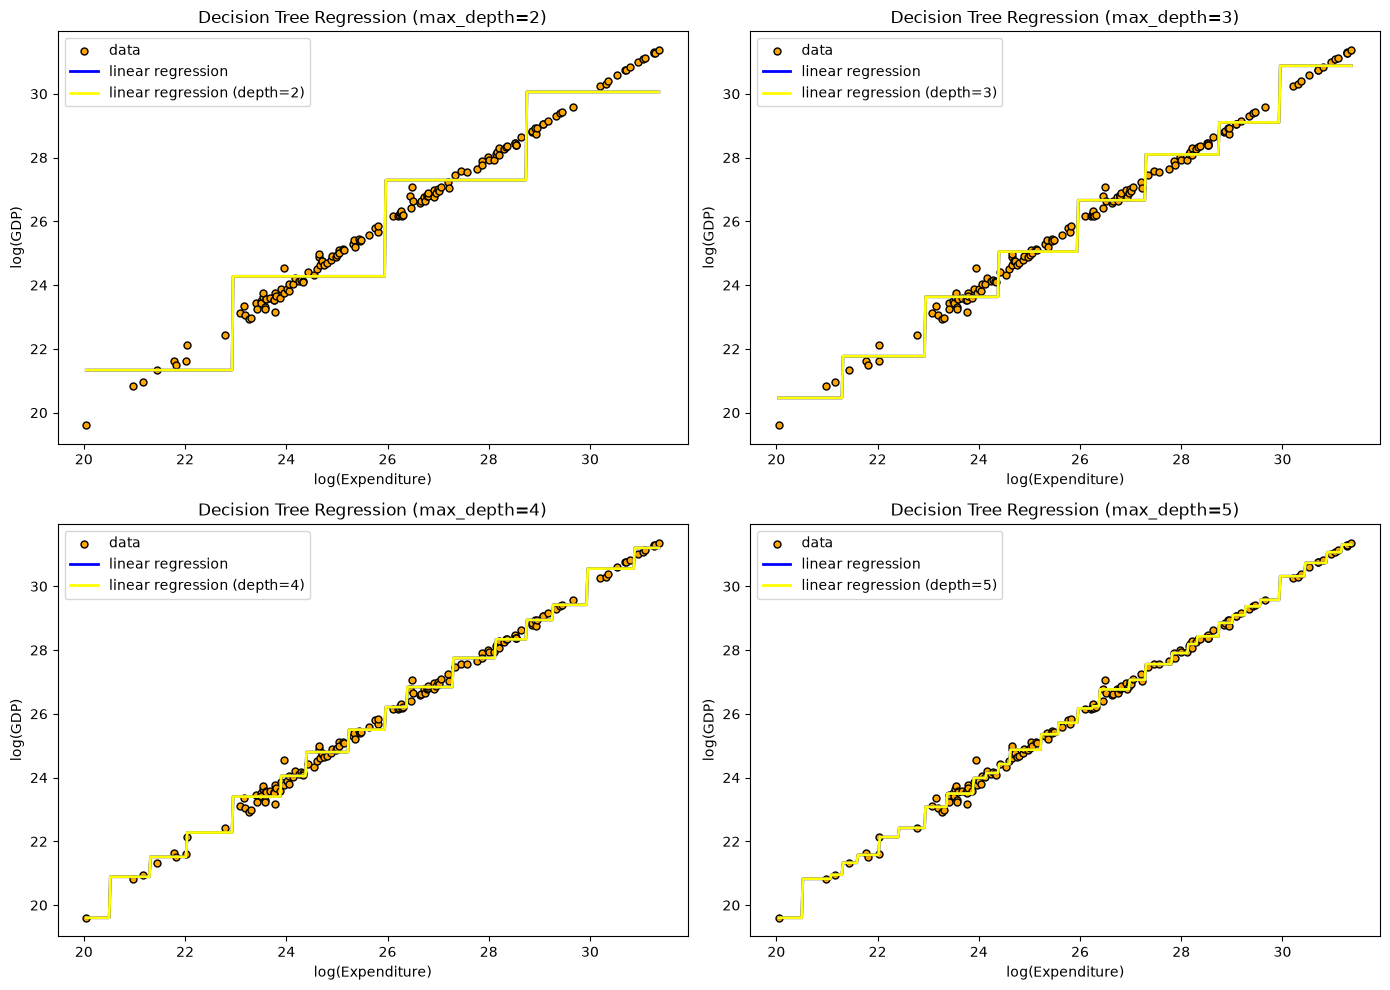

In [24]:
# Linear Rgression vs. Decision Tree Regression 

regr_lin = LinearRegression().fit(x,y)
y_lin = regr_lin.predict(x_test)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
depths = [2, 3, 4, 5]

for ax, depth in zip(axes.ravel(), depths):
    regr_tree = DecisionTreeRegressor(max_depth=depth, random_state=80).fit(x, y)
    y_tree = regr_tree.predict(x_test)

    ax.scatter(x, y, s=25, edgecolor="black", c="orange", label="data")
    ax.plot(x_test, y_tree, color="blue", label="linear regression", linewidth=2)
    ax.plot(x_test, y_tree, color="yellow", label=f"linear regression (depth={depth})", linewidth=2)
    ax.set_xlabel("log(Expenditure)")
    ax.set_ylabel("log(GDP)")
    ax.set_title(f"Decision Tree Regression (max_depth={depth})")
    ax.legend()

plt.tight_layout()
plt.show



In [ ]:
# Define 3-Class Economic Regime Target
# 0 = Healthy   (Unemployment <= 6% and Inflation <= 5%)
# 1 = Recession (Unemployment > 6% and Inflation <= 5%)
# 2 = Stagflation (Inflation > 5%)

def classify_regime(row):
    if row["inflation"] > 6.0:
        return 2 # Stageflation /High-Inflation Regime
    elif row["unemployment"] > 6.0:
        return 1 # Recession / High labour Slack
    else:
        return 0 # Healthy / Macro Stability

df_clean["regime_code"] = df_clean.apply(classify_regime, axis=1)
regime_names = ["Healthy", "Recession", "Stagflation"]
df_clean["economic_state"] = df_clean["regime_code"].map(dict(enumerate(regime_names)))

features = ["unemployment", "inflation"]
x = df_clean[features]
y = df_clean["regime_code"]

# 70% Train / 30% Test Stratified Split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, stratify=y, random_state=42
)

=== Decision Tree Rules ===
|--- unemployment <= 6.08
|   |--- inflation <= 5.81
|   |   |--- class: 0
|   |--- inflation >  5.81
|   |   |--- class: 2
|--- unemployment >  6.08
|   |--- inflation <= 5.53
|   |   |--- class: 1
|   |--- inflation >  5.53
|   |   |--- class: 2

Decision Tree Test Accuracy: 100.00%
              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00        22
   Recession       1.00      1.00      1.00        12
 Stagflation       1.00      1.00      1.00         3

    accuracy                           1.00        37
   macro avg       1.00      1.00      1.00        37
weighted avg       1.00      1.00      1.00        37



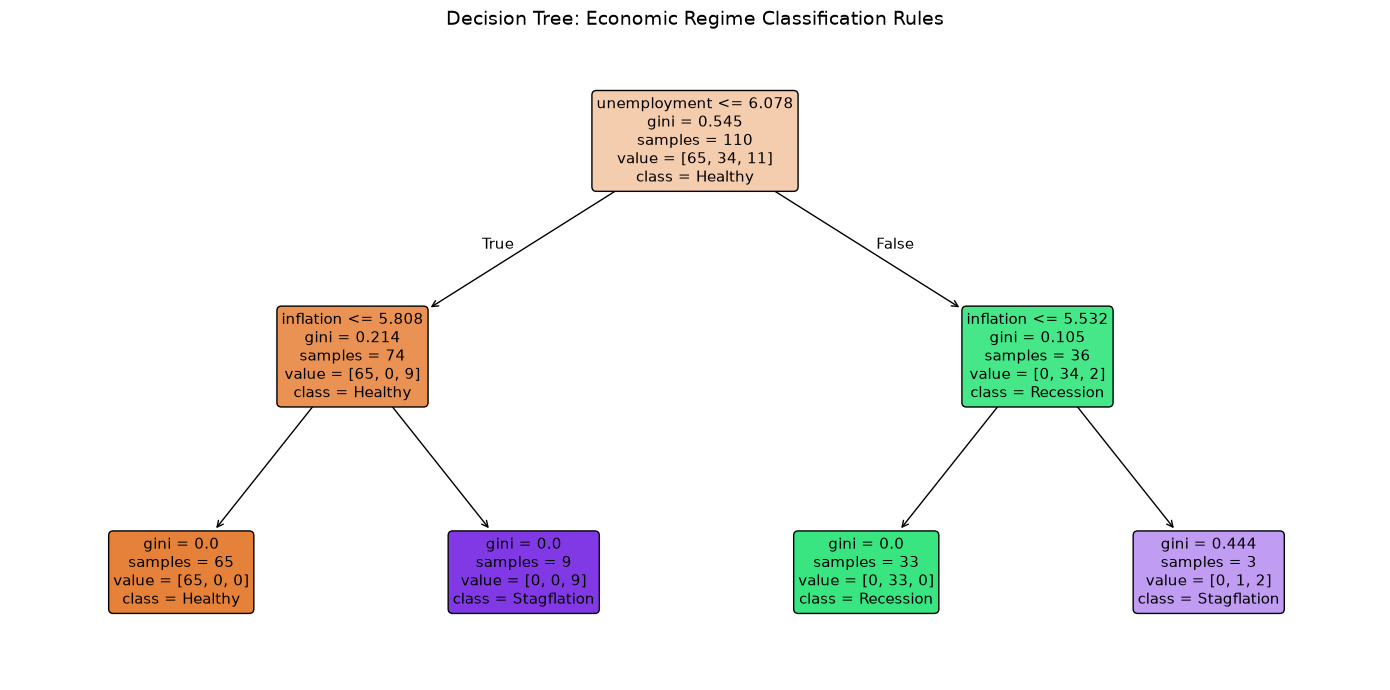

In [ ]:
# Decision Tree Classifier
dt_clf = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=42)
dt_clf.fit(x_train, y_train)

y_pred_dt = dt_clf.predict(x_test)

print("=== Decision Tree Rules ===")
print(export_text(dt_clf, feature_names=features))
print(f"Decision Tree Test Accuracy: {accuracy_score(y_test, y_pred_dt) * 100:.2f}%")
print(classification_report(y_test, y_pred_dt, target_names=regime_names))

# Visualize the Decision Tree Structure
plt.figure(figsize=(14, 7))
plot_tree(
    dt_clf,
    feature_names=features,
    class_names=regime_names,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree: Economic Regime Classification Rules", fontsize=14)
plt.tight_layout()
plt.show()


Random Forest Test Accuracy: 100.00%
              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00        22
   Recession       1.00      1.00      1.00        12
 Stagflation       1.00      1.00      1.00         3

    accuracy                           1.00        37
   macro avg       1.00      1.00      1.00        37
weighted avg       1.00      1.00      1.00        37

=== Random Forest Feature Importances ===
        Feature  Importance
0  unemployment    0.698004
1     inflation    0.301996


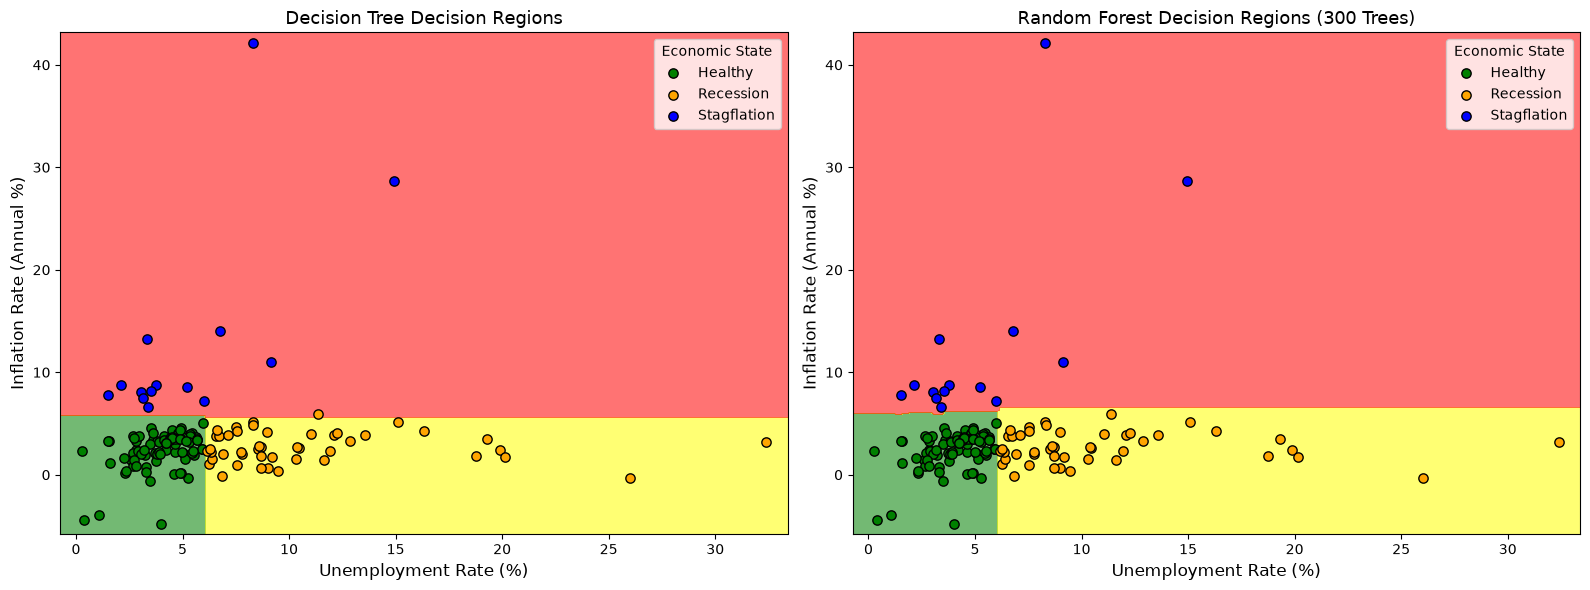

In [ ]:
# ==============================================================================
# 4. Random Forest Classifier
# ==============================================================================
rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    random_state=42
)
rf_clf.fit(x_train, y_train)

y_pred_rf = rf_clf.predict(x_test)

print(f"\nRandom Forest Test Accuracy: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")
print(classification_report(y_test, y_pred_rf, target_names=regime_names))

# Feature Importance Table
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_clf.feature_importances_
}).sort_values(by="Importance", ascending=False)
print("=== Random Forest Feature Importances ===")
print(importance_df)

# ==============================================================================
# 5. Side-by-Side Decision Boundary Comparison Plot
# ==============================================================================
x_min, x_max = X["unemployment"].min() - 1, X["unemployment"].max() + 1
y_min, y_max = X["inflation"].min() - 1, X["inflation"].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
grid_df = pd.DataFrame({"unemployment": xx.ravel(), "inflation": yy.ravel()})

cmap_bg = ListedColormap(["green", "yellow", "red"])
colors  = ["green", "orange", "blue"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, model, title in [
    (axes[0], dt_clf, "Decision Tree Decision Regions"),
    (axes[1], rf_clf, "Random Forest Decision Regions (300 Trees)")
]:
    Z = model.predict(grid_df).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.55, cmap=cmap_bg, levels=[-0.5, 0.5, 1.5, 2.5])
    for code, label, color in zip([0, 1, 2], regime_names, colors):
        sub = df_clean[df_clean["regime_code"] == code]
        ax.scatter(sub["unemployment"], sub["inflation"], c=color, label=label, edgecolors="k", s=45)
    ax.set_xlabel("Unemployment Rate (%)", fontsize=12)
    ax.set_ylabel("Inflation Rate (Annual %)", fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(title="Economic State")

plt.tight_layout()
plt.show()